# BITS Pilani — M.Tech (AIML)
## Machine Learning — Assignment 2: Student Depression Classification & Model Comparison
**Author:** Student Submission  
**Dataset:** Student Depression Dataset (`Datasets/Student_Depression_Dataset.csv`)  
**Task:** Train and compare 5 Classification Models across 6 Evaluation Metrics (Accuracy, AUC, Precision, Recall, F1, MCC) with Confusion Matrices and ROC Analysis

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

%matplotlib inline
sns.set_theme(style="whitegrid")

### 1. Load Dataset & Exploratory Analysis

In [2]:
data_candidates = [
    "../Datasets/Student_Depression_Dataset.csv",
    "Datasets/Student_Depression_Dataset.csv",
    "../Datasets/Student Depression Dataset.csv",
    "Datasets/Student Depression Dataset.csv"
]

data_path = None
for p in data_candidates:
    if os.path.exists(p):
        data_path = p
        break

df = pd.read_csv(data_path)
print(f"Loaded dataset from: {data_path}")
print(f"Dataset Shape: {df.shape}")
df.head()

Loaded dataset from: ../Datasets/Student_Depression_Dataset.csv
Dataset Shape: (27901, 18)


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [3]:
# Dataset Summary
print("Column Data Types and Missing Values:")
print(df.isnull().sum())
print()
print("Target Variable (Depression) Distribution:")
print(df['Depression'].value_counts(normalize=True))

Column Data Types and Missing Values:
id                                       0
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         3
Family History of Mental Illness         0
Depression                               0
dtype: int64

Target Variable (Depression) Distribution:
Depression
1    0.585499
0    0.414501
Name: proportion, dtype: float64


### 2. Preprocessing & Train/Test Split

In [4]:
# Drop ID column if present
if 'id' in df.columns:
    df = df.drop(columns=['id'])

X = df.drop(columns=['Depression'])
y = df['Depression']

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Export test dataset to Datasets/ and project root
test_df = pd.concat([X_test, y_test], axis=1)
os.makedirs("../Datasets", exist_ok=True)
test_df.to_csv("../Datasets/test_data.csv", index=False)
test_df.to_csv("../test_data.csv", index=False)
print(f"Train samples: {len(X_train):,}, Test samples: {len(X_test):,}")

Train samples: 22,320, Test samples: 5,581


In [5]:
# Build Preprocessor Pipeline
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols)
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

os.makedirs("../model", exist_ok=True)
joblib.dump(preprocessor, "../model/preprocessor.joblib")
print(f"Processed feature matrix dimension: {X_train_proc.shape[1]} features")

Processed feature matrix dimension: 111 features


### 3. Model Training & Evaluation Across 6 Metrics

In [6]:
models = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=7, min_samples_leaf=10, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1),
    "Naive Bayes": GaussianNB(var_smoothing=1e-1),
    "Support Vector Machine": SVC(kernel="rbf", C=1.0, probability=True, random_state=42)
}

results = []
predictions_dict = {}

for name, model in models.items():
    print(f"Training {name}...")
    if name == "Support Vector Machine":
        idx = np.random.RandomState(42).choice(len(X_train_proc), size=min(6000, len(X_train_proc)), replace=False)
        model.fit(X_train_proc[idx], y_train.iloc[idx])
    elif name == "KNN":
        idx = np.random.RandomState(42).choice(len(X_train_proc), size=min(8000, len(X_train_proc)), replace=False)
        model.fit(X_train_proc[idx], y_train.iloc[idx])
    else:
        model.fit(X_train_proc, y_train)
        
    y_pred = model.predict(X_test_proc)
    y_prob = model.predict_proba(X_test_proc)[:, 1] if hasattr(model, "predict_proba") else None
    predictions_dict[name] = (y_pred, y_prob)
    
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else 0.0
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)
    
    results.append({
        "ML Model Name": name,
        "Accuracy": round(acc, 4),
        "AUC": round(auc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4),
        "MCC": round(mcc, 4)
    })

results_df = pd.DataFrame(results)
print("\n" + "=" * 70)
print("EVALUATION RESULTS COMPARISON TABLE:")
print("=" * 70)
print(results_df.to_string(index=False))
results_df

Training Logistic Regression...


Training Decision Tree...
Training KNN...


Training Naive Bayes...
Training Support Vector Machine...


/Users/bhoomikakg/.pyenv/versions/3.14.3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



EVALUATION RESULTS COMPARISON TABLE:
         ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.8436 0.9184     0.8576  0.8788 0.8681 0.6764
         Decision Tree    0.8316 0.8991     0.8481  0.8678 0.8578 0.6516
                   KNN    0.8316 0.9030     0.8284  0.8984 0.8620 0.6503
           Naive Bayes    0.7748 0.9118     0.7291  0.9792 0.8358 0.5591
Support Vector Machine    0.8438 0.9157     0.8568  0.8804 0.8684 0.6766


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8436,0.9184,0.8576,0.8788,0.8681,0.6764
1,Decision Tree,0.8316,0.8991,0.8481,0.8678,0.8578,0.6516
2,KNN,0.8316,0.9030,0.8284,0.8984,0.8620,0.6503
3,Naive Bayes,0.7748,0.9118,0.7291,0.9792,0.8358,0.5591
4,Support Vector Machine,0.8438,0.9157,0.8568,0.8804,0.8684,0.6766


### 4. Confusion Matrices for All 5 Classification Models

In [7]:
# Display text Confusion Matrix & Classification Report for each model
target_names = ["No Depression (0)", "Depression (1)"]

for name, (y_pred, _) in predictions_dict.items():
    cm = confusion_matrix(y_test, y_pred)
    print("=" * 65)
    print(f"CONFUSION MATRIX: {name}")
    print("=" * 65)
    cm_df = pd.DataFrame(
        cm,
        index=["Actual No Depression (0)", "Actual Depression (1)"],
        columns=["Predicted No (0)", "Predicted Yes (1)"]
    )
    print(cm_df)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=target_names, digits=4))
    print()

CONFUSION MATRIX: Logistic Regression
                          Predicted No (0)  Predicted Yes (1)
Actual No Depression (0)              1836                477
Actual Depression (1)                  396               2872

Classification Report:
                   precision    recall  f1-score   support

No Depression (0)     0.8226    0.7938    0.8079      2313
   Depression (1)     0.8576    0.8788    0.8681      3268

         accuracy                         0.8436      5581
        macro avg     0.8401    0.8363    0.8380      5581
     weighted avg     0.8431    0.8436    0.8431      5581


CONFUSION MATRIX: Decision Tree
                          Predicted No (0)  Predicted Yes (1)
Actual No Depression (0)              1805                508
Actual Depression (1)                  432               2836

Classification Report:
                   precision    recall  f1-score   support

No Depression (0)     0.8069    0.7804    0.7934      2313
   Depression (1)     0.8481    0

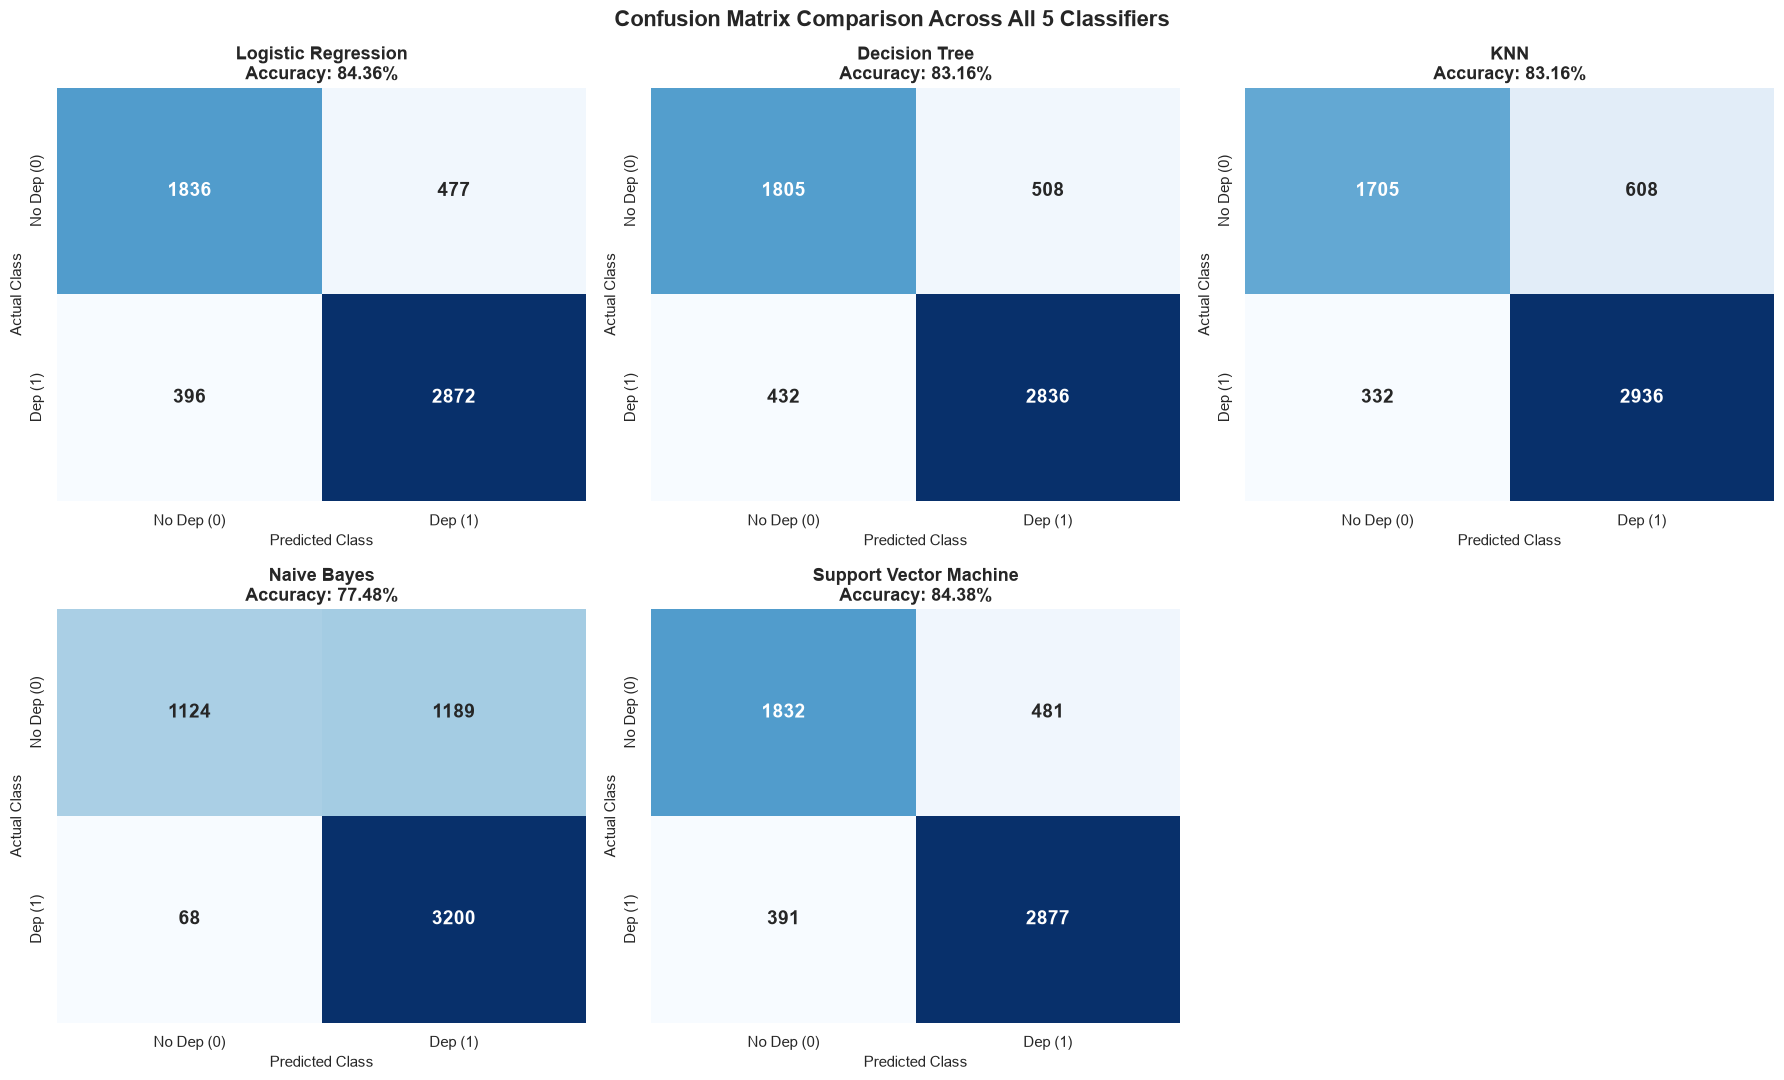

In [8]:
# Plot Confusion Matrix Heatmaps side-by-side in a 2x3 grid
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

class_labels = ["No Dep (0)", "Dep (1)"]

for i, (name, (y_pred, _)) in enumerate(predictions_dict.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[i],
        xticklabels=class_labels,
        yticklabels=class_labels,
        annot_kws={"size": 14, "weight": "bold"}
    )
    axes[i].set_title(f"{name}\nAccuracy: {accuracy_score(y_test, y_pred):.2%}", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Predicted Class", fontsize=11)
    axes[i].set_ylabel("Actual Class", fontsize=11)

# Hide the unused 6th subplot
fig.delaxes(axes[5])

plt.suptitle("Confusion Matrix Comparison Across All 5 Classifiers", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

### 5. Performance Comparison: Metric Bars & Combined ROC Curves

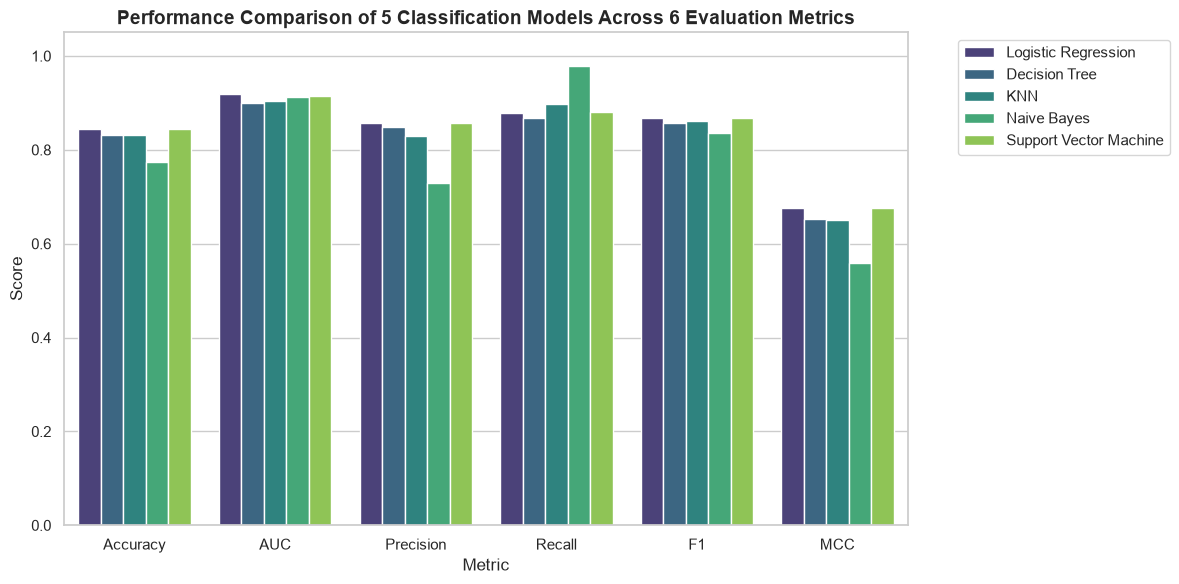

In [9]:
# Metric Comparison Bar Plot
plt.figure(figsize=(12, 6))
melted_df = results_df.melt(id_vars="ML Model Name", var_name="Metric", value_name="Score")
sns.barplot(data=melted_df, x="Metric", y="Score", hue="ML Model Name", palette="viridis")
plt.title("Performance Comparison of 5 Classification Models Across 6 Evaluation Metrics", fontsize=14, fontweight="bold")
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

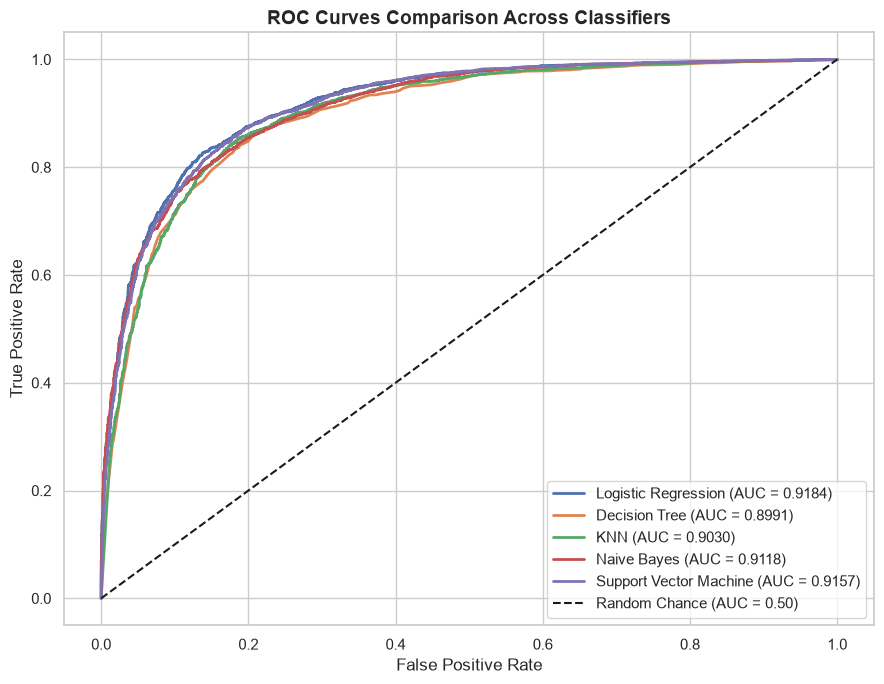

In [10]:
# Combined ROC Curves
plt.figure(figsize=(9, 7))
for name, (y_pred, probs) in predictions_dict.items():
    if probs is not None:
        fpr, tpr, _ = roc_curve(y_test, probs)
        auc_score = roc_auc_score(y_test, probs)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})", linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label="Random Chance (AUC = 0.50)")
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("ROC Curves Comparison Across Classifiers", fontsize=14, fontweight="bold")
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()